<a href="https://colab.research.google.com/github/senchiao/HRRR_plots/blob/main/HRRR_w500mb_DCarea.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install herbie-data xarray cartopy matplotlib metpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 49.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 48.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 11.8 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [herbie-data]


In [2]:
from herbie import Herbie
from herbie.toolbox import EasyMap, pc
from herbie import paint

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

 ╭─▌▌Herbie─────────────────────────────────────────────╮
 │ INFO: Created a default config file.                 │
 │ You may view/edit Herbie's configuration here:       │
 │          /root/.config/herbie/config.toml            │
 ╰──────────────────────────────────────────────────────╯



In [3]:
H = Herbie(
    "2026-11-09",
    model="hrrr",
    product="prs",
    fxx=6,
)
myFile = H.download(verbose=True)
print(myFile)

✅ Found ┊ model=hrrr ┊ product=prs ┊ 2026-Nov-09 00:00 UTC F06 ┊ GRIB2 @ aws ┊ IDX @ aws
👨🏻‍🏭 Created directory: [/root/data/hrrr/20261109]
✅ Success! Downloaded HRRR from aws                 
	src: https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr.20261109/conus/hrrr.t00z.wrfprsf06.grib2
	dst: /root/data/hrrr/20261109/hrrr.t00z.wrfprsf06.grib2
/root/data/hrrr/20261109/hrrr.t00z.wrfprsf06.grib2


In [4]:
# Show available products
H.PRODUCTS

{'sfc': '2D surface level fields; 3-km resolution',
 'prs': '3D pressure level fields; 3-km resolution',
 'nat': 'Native level fields; 3-km resolution',
 'subh': 'Subhourly grids; 3-km resolution'}

In [5]:
# find available products with key words
H.inventory(searchString='VV')

/tmp/ipykernel_1069/1120173154.py:2: DeprecationWarning: The argument `searchString` was renamed `search`. Please update your scripts.
  H.inventory(searchString='VV')


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
5,6,2461640,2718138.0,2461640-2718138,2026-11-09,2026-11-09 06:00:00,VVEL,50 mb,6 hour fcst,:VVEL:50 mb:6 hour fcst:
19,20,7090174,7481056.0,7090174-7481056,2026-11-09,2026-11-09 06:00:00,VVEL,75 mb,6 hour fcst,:VVEL:75 mb:6 hour fcst:
33,34,11959905,12422359.0,11959905-12422359,2026-11-09,2026-11-09 06:00:00,VVEL,100 mb,6 hour fcst,:VVEL:100 mb:6 hour fcst:
47,48,17124209,17639598.0,17124209-17639598,2026-11-09,2026-11-09 06:00:00,VVEL,125 mb,6 hour fcst,:VVEL:125 mb:6 hour fcst:
61,62,22290621,22824721.0,22290621-22824721,2026-11-09,2026-11-09 06:00:00,VVEL,150 mb,6 hour fcst,:VVEL:150 mb:6 hour fcst:
75,76,28108693,28666972.0,28108693-28666972,2026-11-09,2026-11-09 06:00:00,VVEL,175 mb,6 hour fcst,:VVEL:175 mb:6 hour fcst:
89,90,33843070,34414073.0,33843070-34414073,2026-11-09,2026-11-09 06:00:00,VVEL,200 mb,6 hour fcst,:VVEL:200 mb:6 hour fcst:
103,104,39925687,40508163.0,39925687-40508163,2026-11-09,2026-11-09 06:00:00,VVEL,225 mb,6 hour fcst,:VVEL:225 mb:6 hour fcst:
117,118,46248834,46838913.0,46248834-46838913,2026-11-09,2026-11-09 06:00:00,VVEL,250 mb,6 hour fcst,:VVEL:250 mb:6 hour fcst:
131,132,52577461,53185206.0,52577461-53185206,2026-11-09,2026-11-09 06:00:00,VVEL,275 mb,6 hour fcst,:VVEL:275 mb:6 hour fcst:


In [6]:
ds = H.xarray("VVEL:700 mb")
#t700 = ds.t-273.15
print(ds)

<xarray.Dataset> Size: 38MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    time                 datetime64[ns] 8B 2026-11-09
    step                 timedelta64[ns] 8B 06:00:00
    isobaricInhPa        float64 8B 700.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           datetime64[ns] 8B 2026-11-09T06:00:00
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    w                    (y, x) float32 8MB -0.1463 -0.1463 ... 0.4162 0.51
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 prs
    description:             High-Res

In [7]:
# temperature at 700 hPa
ds = H.xarray("VVEL:500 mb") # 700 mb temperature
w500 = ds.w
print(w500)

ds = H.xarray("HGT:500 mb") # 700 mb height
hgt = ds.gh
print(hgt)

<xarray.DataArray 'w' (y: 1059, x: 1799)> Size: 8MB
array([[-0.38406563, -0.35281563, -0.32156563, ..., -0.16531563,
        -0.16531563, -0.16531563],
       [-0.35281563, -0.32156563, -0.32156563, ..., -0.16531563,
        -0.16531563, -0.16531563],
       [-0.35281563, -0.32156563, -0.29031563, ..., -0.16531563,
        -0.16531563, -0.16531563],
       ...,
       [-0.29031563, -0.16531563, -0.07156563, ..., -0.16531563,
        -0.22781563, -0.25906563],
       [-0.32156563, -0.19656563, -0.07156563, ..., -0.19656563,
        -0.25906563, -0.32156563],
       [-0.32156563, -0.19656563, -0.10281563, ..., -0.25906563,
        -0.29031563, -0.35281563]], shape=(1059, 1799), dtype=float32)
Coordinates:
    time                 datetime64[ns] 8B 2026-11-09
    step                 timedelta64[ns] 8B 06:00:00
    isobaricInhPa        float64 8B 500.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 23

Text(1.0, 1.0, 'Geopotential height')

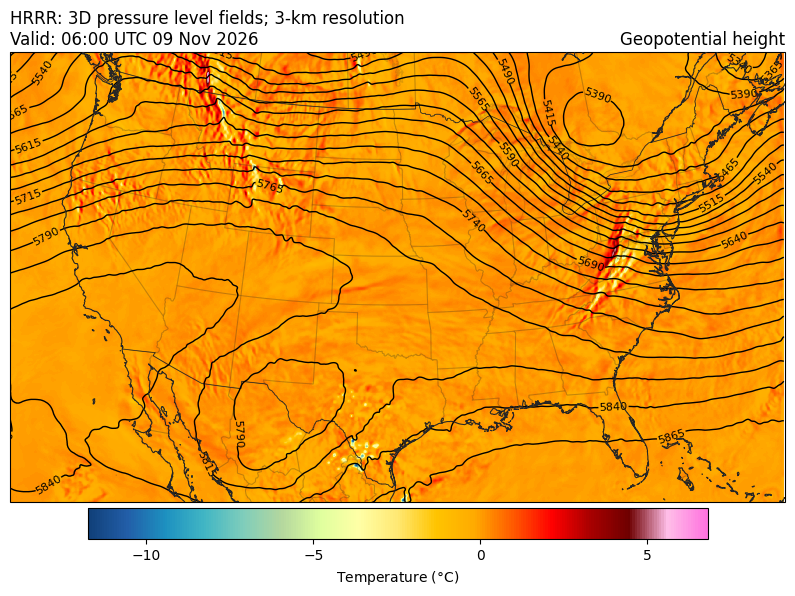

In [21]:
#plot 2m temperature
ax = EasyMap("10m", crs=ds.herbie.crs, figsize=[10, 8]).BORDERS().STATES().ax
#ax = plt.axes(projection=ccrs.LambertConformal())

ax.set_extent([-123, -71, 25, 50], crs=ccrs.PlateCarree()) # for the plotting area
p = ax.pcolormesh(ds.longitude, ds.latitude, w500, cmap="nws.wind", transform=pc)
#p = ax.pcolormesh(
#    ds.longitude,
#    ds.latitude,
#    t700,
#    transform=pc,
#    **paint.NWSTemperature.kwargs2,
#)
plt.colorbar(
    p,
    ax=ax,
    orientation="horizontal",
    pad=0.01,
    shrink=0.8,
    **paint.NWSTemperature.cbar_kwargs2,
)

# Plot Height contours
levels = np.arange(np.floor(hgt.min()), np.ceil(hgt.max()), 25)
#print(levels)
cs = ax.contour(
    hgt["longitude"], hgt["latitude"], hgt,
    levels=levels, colors="black", linewidths=1,
    transform=ccrs.PlateCarree()
)
ax.clabel(cs, inline=True, inline_spacing=1, fontsize=8, fmt="%.0f")

ax.set_title(
    f"{ds.model.upper()}: {H.product_description}\nValid: {ds.valid_time.dt.strftime('%H:%M UTC %d %b %Y').item()}",
    loc="left",
)
ax.set_title(hgt.GRIB_name, loc="right")

In [9]:
ds = H.xarray("MSLMA:mean sea level") # Mean Sea Level Pressure
mslp = ds.mslma/100.
#print(mslp)

[ 987.  989.  991.  993.  995.  997.  999. 1001. 1003. 1005. 1007. 1009.
 1011. 1013. 1015. 1017. 1019. 1021.]


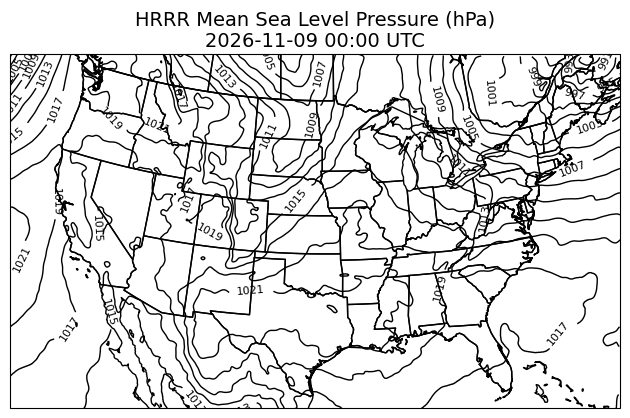

Text(1.0, 1.0, 'MSLP (MAPS System Reduction)')

In [23]:
#ax = EasyMap("50m", crs=ds.herbie.crs, figsize=[10, 8]).BORDERS().STATES().ax
ax = plt.axes(projection=ccrs.LambertConformal())
ax.set_extent([-123, -71, 25, 50], crs=ccrs.PlateCarree())

#Add map features
ax.add_feature(cfeature.COASTLINE.with_scale("50m"))
ax.add_feature(cfeature.BORDERS.with_scale("50m"))
ax.add_feature(cfeature.STATES.with_scale("50m"))

levels = np.arange(np.floor(mslp.min()), np.ceil(mslp.max()), 2.)
print(levels)
cs = ax.contour(
    mslp["longitude"], mslp["latitude"], mslp,
    levels=levels, colors="black", linewidths=1,
    transform=ccrs.PlateCarree()
)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.0f")

plt.title(f"HRRR Mean Sea Level Pressure (hPa)\n{H.date:%Y-%m-%d %H:%M UTC}", fontsize=14)
plt.tight_layout()
plt.show()

ax.set_title(
    f"{ds.model.upper()}: {H.product_description}\nValid: {ds.valid_time.dt.strftime('%H:%M UTC %d %b %Y').item()}",
    loc="left",
)
ax.set_title(ds.mslma.GRIB_name, loc="right")